# Analysis of Popular Caucasian Songs (Yandex.Music Top Chart) with Spotify

Yandex.Music sorts tracks into genres.

The "Caucasian music" genre has about 500 tracks.

Caucasian music has its own particular features (some tracks become surprisingly popular outside the Caucasus, even though their ethnic character outweighs current music trends).

It's interesting to see whether a track's popularity depends on its musical parameters.

The tracks' metadata comes from Spotify (numeric measures of a song's danceability, mood, liveness, and so on), and the analysis checks whether these affect how many times a track is played (Spotify provides that number too).

[More about the metadata.](https://developer.spotify.com/documentation/web-api/reference/tracks/get-audio-features/)

Importing the modules and building the table for analysis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn import datasets, linear_model
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.manifold import TSNE

%matplotlib inline

df = pd.read_csv('caucasus_music.csv')
df.head()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,...,track_name,artist_name,release_date,release_date_num,track_popularity,album_name,artist_id,total_tracks,track_number,tracks_external_id
0,0.90,0.61,8.0,-9.50,0.0,0.10,0.16,0.05,0.10,0.84,...,Дико дикая,ЭGO,2019-11-29,43798,24,Дико дикая,6z0RqMOlBhJ1zgjcN5bw6d,1,1,FRX201934616
1,0.75,0.72,2.0,-6.69,1.0,0.04,0.37,0.02,0.23,0.59,...,неволновайся,Салам,2019-11-28,43797,6,неволновайся,5Exan8U6vUA0AGDvVavzsD,1,1,FRX201946473
2,0.86,0.59,10.0,-6.26,0.0,0.04,0.08,0.00,0.11,0.47,...,Хайям,Tural Everest,2019-11-26,43795,16,Хайям,1GAgS4w3PCCjbA6JKEmlLc,1,1,FRX201929596
3,0.69,0.97,0.0,-3.44,0.0,0.25,0.23,0.00,0.07,0.75,...,Царица ночи,Шамиль Кашешов,2019-11-22,43791,5,Царица ночи,5Cf8wc0BieFpCUdrY1eHrE,1,1,FRX201926928
4,0.43,0.81,10.0,-3.01,0.0,0.06,0.33,0.00,0.07,0.96,...,Дели,Арни Пашаян,2019-11-21,43790,1,Дели,28gc6lv2h6JqzvXi4TwNYx,1,1,FRX201926929


How the songs' "mood" (valence) depends on their "danceability."

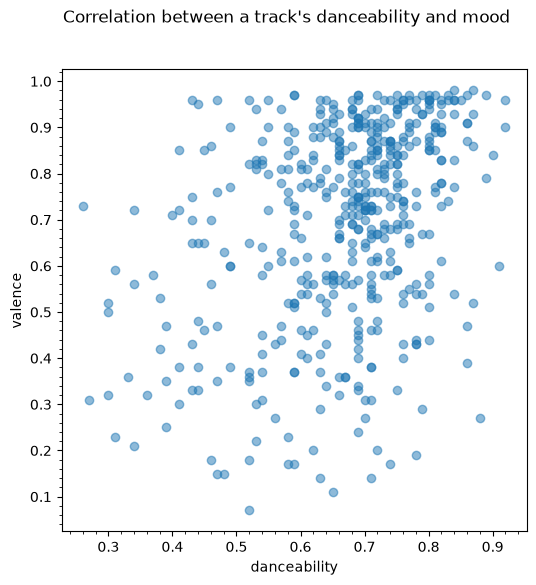

In [2]:
x = df['danceability'].values
y = df['valence'].values

x = x.reshape(x.shape[0], 1)
y = y.reshape(y.shape[0], 1)

fig = plt.figure(figsize=(6, 6))
fig.suptitle("Correlation between a track's danceability and mood")
ax = plt.subplot(1, 1, 1)
ax.scatter(x, y, alpha=0.5)
plt.xticks(())
plt.yticks(())

ax.xaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.02))

ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.02))

plt.xlabel('danceability')
plt.ylabel('valence')

plt.show()

Two histograms: the chart on the left shows how the songs are distributed by "energy," and the one on the right is a "heat map" showing where "mood" and "danceability" values intersect.

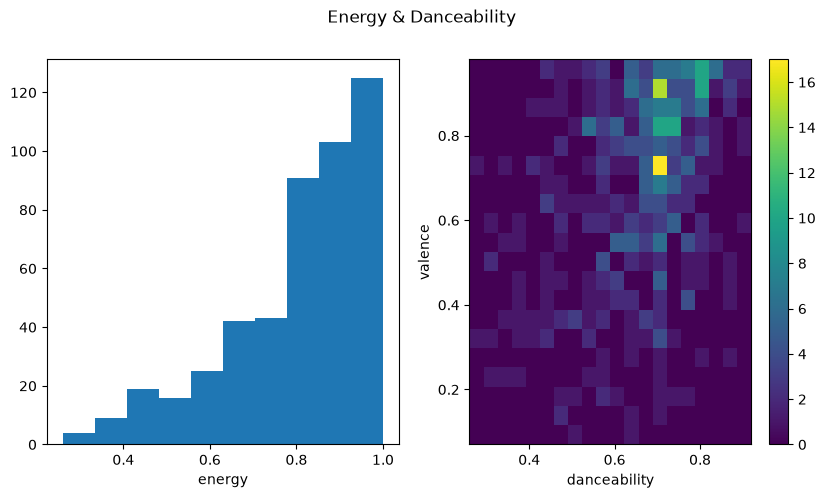

In [3]:
x = "danceability"
y = "valence"

fig, (ax1, ax2) = plt.subplots(1, 2, sharey=False, sharex=False, figsize=(10, 5))
fig.suptitle("Energy & Danceability")
h = ax2.hist2d(df[x], df[y], bins=20)
ax1.hist(df["energy"])

ax2.set_xlabel(x)
ax2.set_ylabel(y)

ax1.set_xlabel("energy")

plt.colorbar(h[3], ax=ax2)

plt.show()

A new list of the selected metadata that are most interesting for the analysis.

Next, PCA (*principal component analysis*) reduces the dimensionality of this list to 3, creating a matrix suitable for the 3D chart below.

The smaller the distance between any two songs, the more similar their features.

In [4]:
!conda install plotly --yes

import plotly.offline as py
py.init_notebook_mode(connected=True)
import plotly.graph_objs as go
import plotly.tools as tls

chosen = ["energy", "liveness", "tempo", "valence", "loudness", "speechiness", "acousticness", "danceability", "instrumentalness"]
X = df[chosen].values
y = df["danceability"].values

text = df['artist_name'] + " - " + df['track_name']
text_plot = text.values

min_max_scaler = MinMaxScaler()
X = min_max_scaler.fit_transform(X)

pca = PCA(n_components=3)
pca.fit(X)

X = pca.transform(X)

trace = go.Scatter3d(
    x=X[:,0],
    y=X[:,1],
    z=X[:,2],
    text = text_plot,
    mode="markers",
    marker=dict(
        size=8,
        color=y
    )
)

fig = go.Figure(data=[trace])
py.iplot(fig, filename="test-graph")

Solving environment: done

# All requested packages already installed.



Another attempt uses a list with fewer metadata and PCA to make a 2D chart.

In [5]:
chosen2 = ['energy', 'liveness', 'tempo', 'valence']

X = df[chosen2].values
y = df['track_popularity'].values

min_max_scaler = MinMaxScaler()
X = min_max_scaler.fit_transform(X)

pca = PCA(n_components=2)
pca.fit(X)

X = pca.transform(X)

fig = {
    "data": [
        {
            "x": X[:, 0],
            "y": X[:, 1],
            "text": text_plot,
            "mode": "markers",
            "marker": {"size": 8, "color": y}
        }
    ],
    "layout": {
        "xaxis": {"title": "How danceable is this song?"},
        "yaxis": {"title": "How often do people listen to this song?"}
    }
}

py.iplot(fig, filename="test-graph2")

And finally, a chart using the list of selected values and t-SNE (t-distributed stochastic neighbor embedding).

In [6]:
import time

chosen = ["energy", "liveness", "tempo", "valence", "loudness",
          "speechiness", "acousticness", "danceability", "instrumentalness"]

X = df[chosen].values
y = df["track_popularity"].values

min_max_scaler = MinMaxScaler()
X = min_max_scaler.fit_transform(X)

time_start = time.time()
tsne = TSNE(n_components=2, verbose=1, perplexity=40, n_iter=300)
tsne_results = tsne.fit_transform(X)

print('t-SNE done! Time elapsed: {} seconds'.format(time.time()-time_start))

[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 477 samples in 0.003s...
[t-SNE] Computed neighbors for 477 samples in 0.031s...
[t-SNE] Computed conditional probabilities for sample 477 / 477
[t-SNE] Mean sigma: 0.203367
[t-SNE] KL divergence after 250 iterations with early exaggeration: 65.231453
[t-SNE] KL divergence after 300 iterations: 0.926925
t-SNE done! Time elapsed: 1.5636286735534668 seconds


In [7]:
fig = {
    "data": [
        {
            "x": tsne_results[:, 0],
            "y": tsne_results[:, 1],
            "text": text_plot,
            "mode": "markers",
            "marker": {"size": 8, "color": y}
        }
    ],
    "layout": {
        "xaxis": {"title": "x-tsne"},
        "yaxis": {"title": "y-tsne"}
    }
}

py.iplot(fig, filename="test-graph2")